In [20]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
import optuna
import sys
from pathlib import Path
import torch # Torch needs to be installed manually if you want cuda. See installation command on pytorch website
import warnings

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

warnings.filterwarnings("ignore")

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
SEED = 987
TRACK = "off_market"                     # "off_market" or "list_aware"
VAL_START = pd.Timestamp("2025-12-01")    # sales on or after this date are validation
N_TRIALS = 10                             # optuna trials
N_ESTIMATORS = 2000                      # max boosting rounds per trial
EARLY_STOPPING_ROUNDS = 100
ES_FRACTION = 0.1                         # latest share of each fold's training rows used for early stopping
K_FOLDS = 5                              # time series cross validation folds
DEBUG = True                             # print MdAPE and MAPE for every fold

In [22]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

In [23]:
from xxbonkxx_features import off_market_features, list_aware_features

make_features = off_market_features if TRACK == "off_market" else list_aware_features

train = listings[listings["date_sold"] < VAL_START]
val = listings[listings["date_sold"] >= VAL_START]

X_train = make_features(train)
X_val = make_features(val)

y_train = np.log(train["sold_price"])
y_val = np.log(val["sold_price"])
# y_train = train["sold_price"]
# y_val = val["sold_price"]

print(f"Features: {X_train.columns.tolist()}")
print(f"train: {len(train):,} sales up to {VAL_START.date()}")
print(f"val:   {len(val):,} sales from {VAL_START.date()}")

Features: ['house_area_was_range', 'square_feet', 'bedrooms', 'washrooms', 'parking', 'lot_front', 'lot_depth', 'lot_missing', 'latitude', 'longitude', 'municipality', 'community', 'is_apartment', 'month', 'year', 'day', 'lag_annual', 'lag_semi_annual']
train: 139,931 sales up to 2025-12-01
val:   10,069 sales from 2025-12-01


In [24]:
def mdape_log(y_log, pred_log):
    return 100 * np.median(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mape_log(y_log, pred_log):
    return 100 * np.mean(np.abs(np.exp(pred_log) / np.exp(y_log) - 1))

def mdape(y, pred):
    return 100 * np.median(np.abs(pred - y) / np.abs(y))

def mape(y, pred):
    return 100 * np.mean(np.abs(pred - y) / np.abs(y))

target_space = "log"

In [25]:
from sklearn.model_selection import TimeSeriesSplit


def cross_val(X, y, params, K=5, debug=False, target_space="log"):
    """Walk-forward K-fold: each fold trains on every row before its validation block.
    X and y must be sorted by time (listings is sorted by date_sold).
    Early stopping uses the latest ES_FRACTION of each fold's training rows, never the
    validation block, so the fold scores are honest.
    Returns (mean validation loss, mean boosting rounds used) over the folds."""
    mdape_scores = []
    mape_scores = []
    rounds = []
    for fold, (train_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=K).split(X), start=1):
        n_fit = int(len(train_idx) * (1 - ES_FRACTION))
        fit_idx, es_idx = train_idx[:n_fit], train_idx[n_fit:]
        X_fit, X_es, X_va = X.iloc[fit_idx], X.iloc[es_idx], X.iloc[val_idx]
        y_fit, y_es, y_va = y.iloc[fit_idx], y.iloc[es_idx], y.iloc[val_idx]

        model = XGBRegressor(**params, device=DEVICE, n_estimators=N_ESTIMATORS,
                             early_stopping_rounds=EARLY_STOPPING_ROUNDS, random_state=SEED)
        model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
        rounds.append(model.best_iteration + 1)
        pred = model.predict(X_va)
        if target_space == "log":
            mdape_scores.append(mdape_log(y_va, pred))
        else:
            mdape_scores.append(mdape(y_va, pred))

        if target_space == "log":
            mape_scores.append(mape_log(y_va, pred))
        else:
            mape_scores.append(mape(y_va, pred))

        if debug:
            mdape_error = mdape_scores[-1]
            mape_error = mape_scores[-1]
            print(f"fold {fold}: train {len(fit_idx):,}  early stop {len(es_idx):,}  val {len(val_idx):,}  "
                  f"rounds {rounds[-1]}  MdAPE {mdape_error:.2f}%  MAPE {mape_error:.2f}%", flush=True)

    print(f"mean MdAPE {np.mean(mdape_scores):.2f}%  mean MAPE {np.mean(mape_scores):.2f}%", flush=True)
    return np.mean(mdape_scores), int(np.mean(rounds))

In [26]:
def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, step=0.01),
        "max_depth": trial.suggest_int("max_depth", 3, 13),
        "subsample": trial.suggest_float("subsample", 0.1, 1.0, step=0.1),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.1, 1.0, step=0.1),
        "max_bin": trial.suggest_int("max_bin", 256, 2048),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 0.1, step=0.01),
        "lambda": trial.suggest_float("lambda", 1e-3, 10.0, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 10.0, log=True),
        "max_delta_step": trial.suggest_int("max_delta_step", 1, 10),
        "enable_categorical": True,
    }
    score, n_rounds = cross_val(X_train, y_train, params, K=K_FOLDS, debug=DEBUG, target_space=target_space)
    trial.set_user_attr("n_rounds", n_rounds)
    return score

In [27]:
X_train[["lag_annual", "lag_semi_annual"]].tail()

,lag_annual,lag_semi_annual
139926,13.712628,13.587821
139927,13.743205,13.698302
139928,13.611005,13.696051
139929,13.580673,13.792651
139930,13.769450,13.751505


In [28]:
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED), study_name="VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!")
study.optimize(objective, n_trials=N_TRIALS)

print("best CV MdAPE:", round(study.best_value, 2))
print("best params:", study.best_params)
print("boosting rounds:", study.best_trial.user_attrs["n_rounds"])

[I 2026-10-17 20:22:31,439] A new study created in memory with name: VAPE GOD VAPE GOD VAPE GOD 420 420 696969!!!!


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 590  MdAPE 11.09%  MAPE 13.53%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 556  MdAPE 11.54%  MAPE 14.13%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 1187  MdAPE 10.35%  MAPE 12.99%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 1736  MdAPE 10.64%  MAPE 13.53%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 1350  MdAPE 11.50%  MAPE 14.58%
mean MdAPE 11.02%  mean MAPE 13.75%


[I 2026-10-17 20:22:46,946] Trial 0 finished with value: 11.024337445333586 and parameters: {'learning_rate': 0.05, 'max_depth': 7, 'subsample': 0.9, 'colsample_bytree': 0.5, 'max_bin': 1778, 'min_child_weight': 10, 'gamma': 0.1, 'lambda': 7.103714746188992, 'alpha': 0.0013187949354214168, 'max_delta_step': 1}. Best is trial 0 with value: 11.024337445333586.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 513  MdAPE 11.34%  MAPE 13.76%
fold 2: train 41,982  early stop 4,665  val 23,321  rounds 826  MdAPE 11.70%  MAPE 14.54%
fold 3: train 62,971  early stop 6,997  val 23,321  rounds 584  MdAPE 10.91%  MAPE 13.53%
fold 4: train 83,960  early stop 9,329  val 23,321  rounds 621  MdAPE 11.43%  MAPE 14.53%
fold 5: train 104,949  early stop 11,661  val 23,321  rounds 1314  MdAPE 12.02%  MAPE 15.26%
mean MdAPE 11.48%  mean MAPE 14.32%


[I 2026-10-17 20:22:53,019] Trial 1 finished with value: 11.480464490556084 and parameters: {'learning_rate': 0.09, 'max_depth': 3, 'subsample': 0.8, 'colsample_bytree': 0.8, 'max_bin': 808, 'min_child_weight': 3, 'gamma': 0.08, 'lambda': 4.791227993546376, 'alpha': 0.0058203973119644765, 'max_delta_step': 9}. Best is trial 0 with value: 11.024337445333586.


fold 1: train 20,993  early stop 2,333  val 23,321  rounds 2000  MdAPE 11.40%  MAPE 13.86%


[W 2026-10-17 20:23:02,236] Trial 2 failed with parameters: {'learning_rate': 0.05, 'max_depth': 11, 'subsample': 0.7000000000000001, 'colsample_bytree': 0.7000000000000001, 'max_bin': 1891, 'min_child_weight': 9, 'gamma': 0.03, 'lambda': 0.013397845804991282, 'alpha': 4.998638172864346, 'max_delta_step': 5} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/home/koyo-ai/miniconda3/envs/homeless/lib/python3.14/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_601930/2596576536.py", line 15, in objective
    score, n_rounds = cross_val(X_train, y_train, params, K=K_FOLDS, debug=DEBUG, target_space=target_space)
                      ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_601930/2226223732.py", line 21, in cross_val
    model.fit(X_fit, y_fit, eval_set=[(X_es, y_es)], verbose=False)
    ~~~~~~~~~^^^^^

KeyboardInterrupt: 

In [ ]:
from optuna.importance import get_param_importances

importance = get_param_importances(study)

for param, score in importance.items():
    print(f"{param}: {score:.4f}")

lambda: 0.3345
max_bin: 0.1931
alpha: 0.1687
gamma: 0.0873
colsample_bytree: 0.0507
min_child_weight: 0.0360
max_delta_step: 0.0334
max_depth: 0.0333
learning_rate: 0.0317
subsample: 0.0313


In [ ]:
# The validation set is only scored, never used for fitting or early stopping:
# the number of rounds comes from cross validation on the training sales.
model = XGBRegressor(**study.best_params,
                     enable_categorical=True,
                     device=DEVICE,
                     n_estimators=study.best_trial.user_attrs["n_rounds"],
                     random_state=SEED)
model.fit(X_train, y_train, verbose=False)

predicted = np.exp(model.predict(X_val))
error = 100 * np.abs(predicted / val["sold_price"] - 1)
print(f"{TRACK}  MdAPE {error.median():.2f}%  MAPE {error.mean():.2f}%")

off_market  MdAPE 9.35%  MAPE 12.05%


In [ ]:
feature_importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(feature_importances)

lot_missing             0.291539
lot_front               0.180035
square_feet             0.137973
washrooms               0.133256
community               0.069023
lot_depth               0.039055
bedrooms                0.035422
house_type              0.031673
parking                 0.029321
is_apartment            0.009780
day                     0.006460
longitude               0.005716
latitude                0.005521
municipality            0.005505
house_style             0.004807
year                    0.004711
month                   0.004251
lag_annual              0.002249
lag_semi_annual         0.002037
house_area_was_range    0.001666
dtype: float32

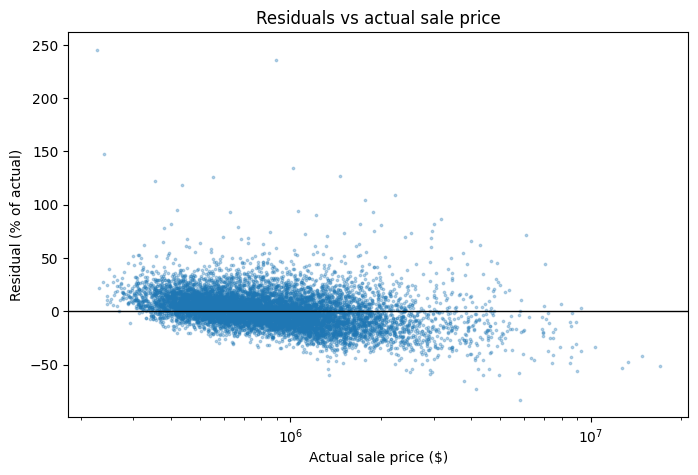

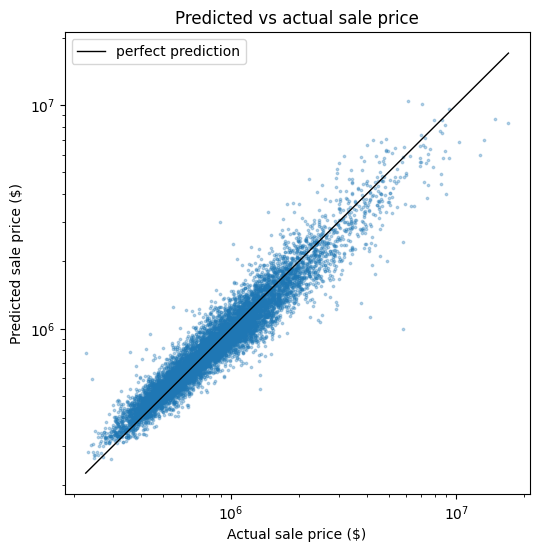

In [ ]:
import diagnostics

actual = val["sold_price"]

diagnostics.plot_residuals_vs_actual(actual, predicted)
diagnostics.plot_predicted_vs_actual(actual, predicted)

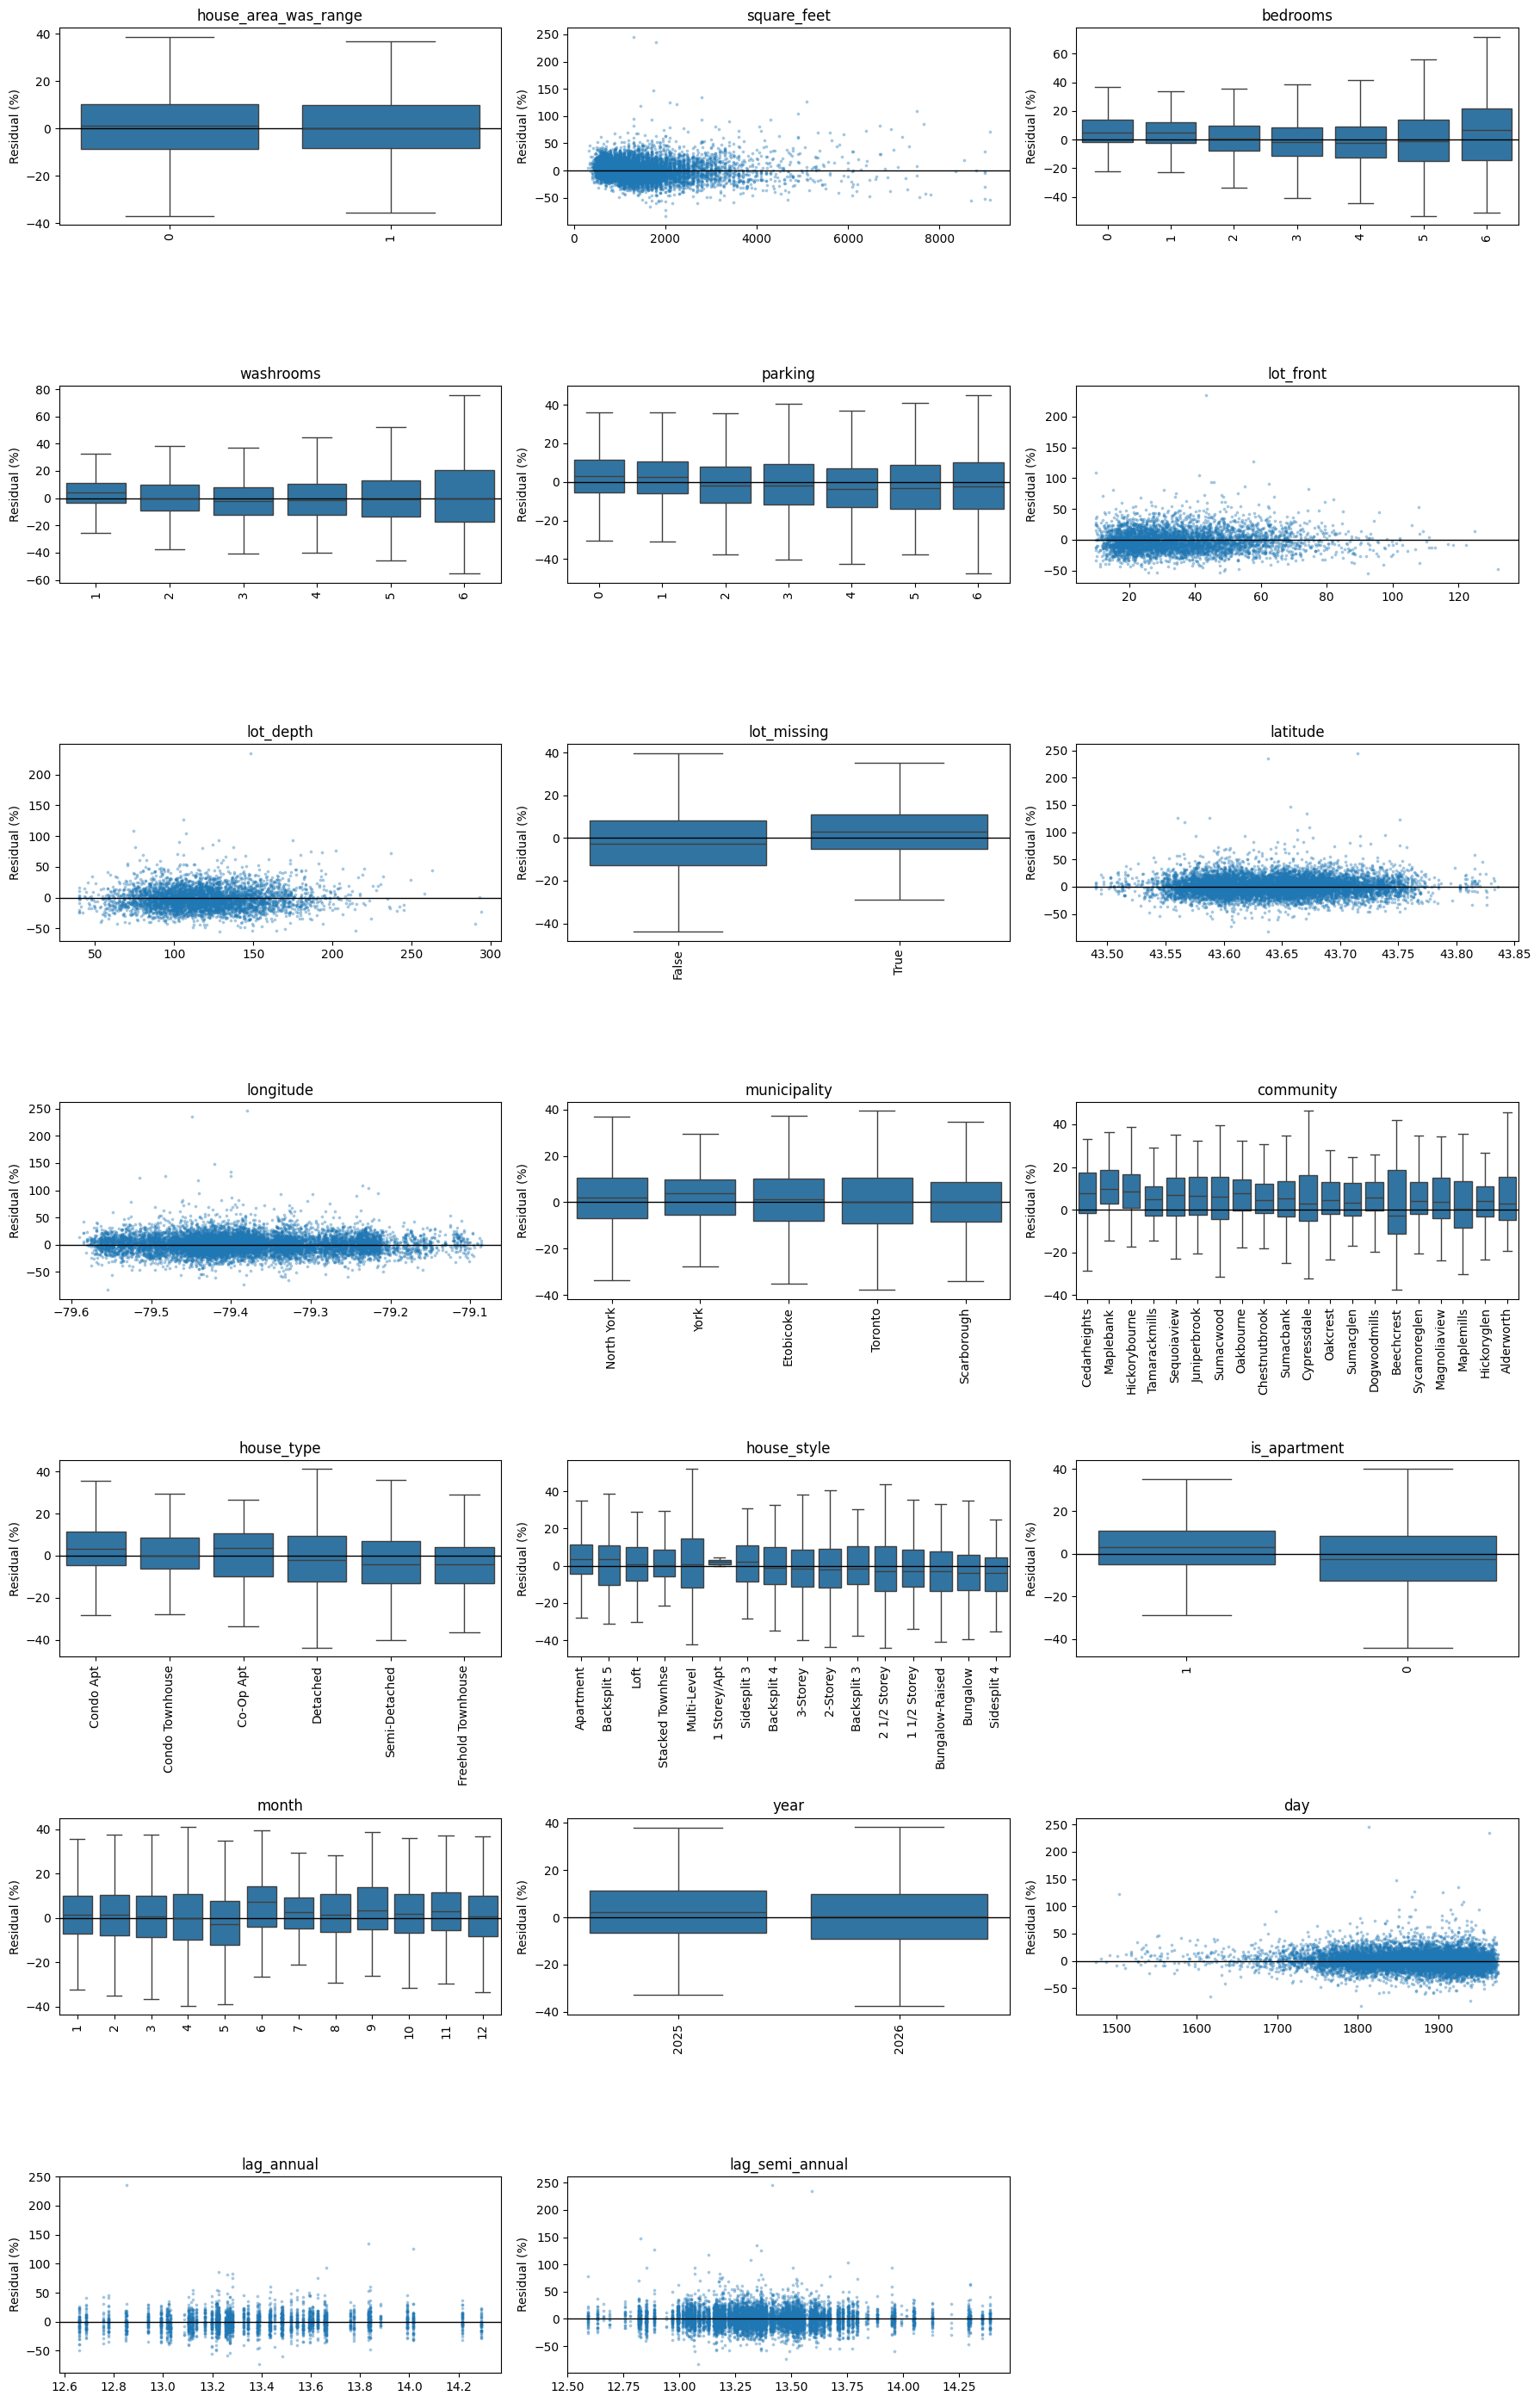

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_residuals_by_feature(X, actual, predicted, max_categories=20, n_cols=3):
    """One panel per column of X: a scatter plot for continuous columns and a box plot
    for categorical ones. Numeric columns with at most max_categories distinct values
    (bedrooms, month, ...) count as categorical. Columns with more categories than that
    show only their max_categories most common values."""
    residual = percent_error(actual, predicted)
    n_rows = int(np.ceil(len(X.columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4 * n_rows), squeeze=False)

    for ax, column in zip(axes.flat, X.columns):
        values = X[column].to_numpy()
        is_numeric = pd.api.types.is_numeric_dtype(X[column])
        if is_numeric and X[column].nunique() > max_categories:
            ax.scatter(values, residual, s=3, alpha=0.3)
        else:
            if is_numeric:
                order = sorted(X[column].value_counts().index[:max_categories])
            else:
                order = (
                    pd.DataFrame({"category": X[column], "residual": residual})
                    .groupby("category")["residual"]
                    .mean()
                    .sort_values(ascending=False)
                    .head(max_categories)
                    .index
                    .tolist()
                )
            sns.boxplot(x=values, y=residual, order=order, showfliers=False, ax=ax)
            ax.tick_params(axis="x", rotation=90)
        ax.axhline(0, color="black", linewidth=1)
        ax.set(title=column, xlabel="", ylabel="Residual (%)")

    for ax in axes.flat[len(X.columns):]:
        ax.set_visible(False)
    fig.tight_layout()
    plt.show()

def percent_error(actual, predicted):
    return 100 * (np.asarray(predicted) / np.asarray(actual) - 1)

plot_residuals_by_feature(X_val, actual, predicted)

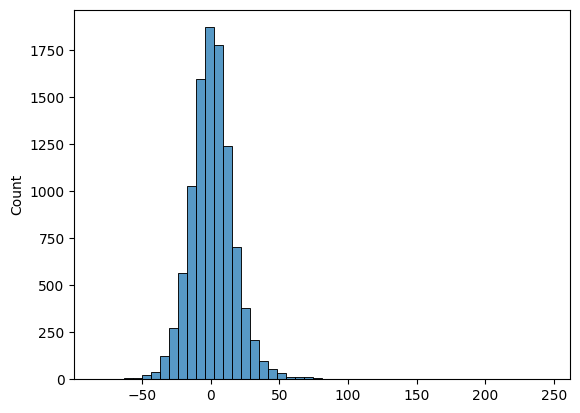

In [29]:
residuals = percent_error(actual, predicted)
sns.histplot(residuals, bins=50)
plt.show()

In [ ]:
def evaluate_by_quantile(y_true, y_pred, n_bins=10):
    df = pd.DataFrame({
        "actual": y_true,
        "predicted": y_pred
    })
    df["quantile"] = pd.qcut(
        df["actual"], q=n_bins, duplicates="drop"
    )
    df["residual"] = df["actual"] - df["predicted"]
    df["residual_percent"] = 100 * np.abs(df["residual"]) / df["actual"]
    return df.groupby("quantile", observed=True).agg(
        count=("actual", "size"),
        MAE=("residual", lambda x: x.abs().mean()),
        mean_residual=("residual", "mean"),
        mean_residual_percent=("residual_percent", "mean"),
        mdape=("residual_percent", lambda x: np.median(np.abs(x))),
        mape=("residual_percent", lambda x: np.mean(np.abs(x)))
    )

evaluate_by_quantile(actual, predicted, n_bins=10)

,count,MAE,mean_residual,mean_residual_percent,mdape,mape
quantile,,,,,,
"(226199.999, 440480.0]",1007,51282.919966,-45410.769520,13.875625,10.660484,13.875625
"(440480.0, 521000.0]",1008,47192.190166,-35620.049107,9.826249,7.628290,9.826249
"(521000.0, 597040.0]",1006,54291.336667,-29752.558959,9.711848,7.059970,9.711848
"(597040.0, 692020.0]",1007,63401.407429,-24084.408733,9.850883,7.702197,9.850883
"(692020.0, 805300.0]",1009,75273.651418,-20696.109483,10.051194,7.705635,10.051194
"(805300.0, 939280.0]",1004,92594.224041,-11743.682458,10.640779,8.276038,10.640779
"(939280.0, 1101060.0]",1007,109452.778116,12218.676825,10.722611,8.727140,10.722611
"(1101060.0, 1316500.0]",1007,152283.942776,50908.580065,12.661673,10.913118,12.661673
"(1316500.0, 1761240.0]",1007,219249.531281,75898.222939,14.576429,12.592771,14.576429
